# Phân loại bình luận Toxic bằng PhoBERT (v2)

Notebook này **fine-tune PhoBERT** (`vinai/phobert-base-v2`), mô hình BERT tiếng Việt được học trước trên khoảng 20 GB văn bản (Wikipedia, tin tức) và 120 GB văn bản từ OSCAR, để phân loại bình luận sản phẩm thành **toxic (1)** hoặc **không toxic (0)**.

**Khác với bản `train_phobert.ipynb`:** bản v2 dùng **bộ dữ liệu chung của dự án** (`data/` ở thư mục gốc repo) và **xuất file nộp TV4** `results/predictions/phobert.csv` + `phobert_info.json` theo `QUY_UOC_FILE_DU_DOAN.md`, để so sánh trực tiếp với Naive Bayes và SVM trong `4_model_evaluation.py`.

**Lưu ý quan trọng:** PhoBERT được học trên văn bản **đã tách từ** (ví dụ `điện_máy_xanh`, `bảo_hành`). Vì vậy câu đầu vào **bắt buộc phải tách từ** theo cùng một cách, cả khi train lẫn khi dự đoán (mục 4).

- **Dữ liệu:** `data/train.csv` (7.000 câu, 240 toxic), `data/val.csv` (1.000 câu, 45 toxic), `data/test.csv` (2.000 câu, 75 toxic).
- **Thiết bị:** tự nhận GPU NVIDIA, Mac Apple Silicon (MPS) hoặc CPU. Nên chạy trên Kaggle (GPU T4).
- **Đầu ra:** file nộp TV4; Accuracy, Precision, Recall, F1, confusion matrix, PR-AUC; đường học; phân tích lỗi; mô hình đã train.

Chạy lần lượt từng cell từ trên xuống. Chỉ cần sửa **cell Cấu hình** (mục 2).

## 1. Cài đặt thư viện
Trên Kaggle và Colab, torch và transformers đã có sẵn, cell này chủ yếu cài thêm `pyvi` (dùng để tách từ tiếng Việt, không cần Java). Cần bật **Internet: On** trong Settings của notebook.

In [1]:
%pip install -q transformers pyvi scikit-learn pandas matplotlib
# Nếu chưa có PyTorch: xem lệnh cài phù hợp với máy tại https://pytorch.org/get-started/locally/

Note: you may need to restart the kernel to use updated packages.


**Chạy trên Kaggle**
1. Gắn dataset **`DATA-NLPV2`** (3 file `train.csv`, `val.csv`, `test.csv` lấy từ thư mục **`data/` ở gốc repo**, test có 2.000 câu; **không** dùng bản `data_v3`) qua **Add Input**.
2. Trong **Settings**: *Accelerator* chọn **GPU T4 x2** (không chọn P100), *Internet* chọn **On** để tải `pyvi` và PhoBERT.
3. Bấm **Save Version → Save & Run All (Commit)** để notebook chạy nền. Kết quả nằm trong `/kaggle/working/` (tab Output).

Cell dưới ưu tiên dataset `DATA-NLPV2` (đường dẫn chứa `data-nlpv2`); nếu không thấy thì tự tìm trong `/kaggle/input` thư mục có `test.csv` đủ 2.000 câu. Nếu không bật được Internet, hãy tải thư mục `models/phobert-base-v2` (tạo bằng `download_models.py`) lên làm dataset; cell dưới cũng tự nhận ra.

**Chạy trên máy:** notebook tự dùng `../data` và ghi kết quả vào `../results/` (thư mục gốc repo).

In [2]:
import os, glob
import pandas as pd

DATASET_NAME = 'data-nlpv2'   # tên dataset trên Kaggle (DATA-NLPV2), viết thường như trong đường dẫn
N_TEST = 2000                 # test.csv chung của dự án có đúng 2.000 câu (quy ước nộp TV4)

if os.path.isdir('/kaggle/input'):
    # tìm thư mục có đủ train/val/test.csv và test.csv đúng 2.000 câu trong các dataset đã gắn
    cands = sorted(os.path.dirname(p) for p in glob.glob('/kaggle/input/**/train.csv', recursive=True)
                   if all(os.path.exists(os.path.join(os.path.dirname(p), f)) for f in ('val.csv', 'test.csv')))
    sizes = {d: len(pd.read_csv(os.path.join(d, 'test.csv'))) for d in cands}
    found = [d for d, n in sizes.items() if n == N_TEST]
    found.sort(key=lambda d: DATASET_NAME not in d.lower())   # ưu tiên DATA-NLPV2
    assert found, (f'Không thấy bộ dữ liệu có test.csv {N_TEST} câu trong /kaggle/input (tìm được: {sizes}). '
                   'Hãy gắn dataset DATA-NLPV2 (tạo từ thư mục data/ ở gốc repo) qua "Add Input".')
    DATA_DIR_OVERRIDE = found[0]
    if DATASET_NAME not in DATA_DIR_OVERRIDE.lower():
        print(f'Cảnh báo: không thấy dataset {DATASET_NAME}, dùng tạm thư mục khác.')
    print('Dữ liệu:', DATA_DIR_OVERRIDE)

    # nếu PhoBERT được tải lên làm dataset thì dùng bản đó, không cần tải từ Hugging Face
    local = glob.glob('/kaggle/input/**/bpe.codes', recursive=True)
    if local:
        os.environ['PHOBERT_MODEL'] = os.path.dirname(local[0])
        print('Mô hình (offline):', os.environ['PHOBERT_MODEL'])

Dữ liệu: /kaggle/input/datasets/dnggnguyn/data-nlpv2


## 2. Cấu hình

In [3]:
import os, json, time, random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Chạy trên máy (notebook nằm trong toxic_classification/): đọc ../data, ghi vào ../results
ROOT       = '..' if os.path.exists('../4_model_evaluation.py') else '.'
DATA_DIR   = globals().get('DATA_DIR_OVERRIDE', os.path.join(ROOT, 'data'))   # thư mục chứa train/val/test.csv
OUT_DIR    = os.path.join(ROOT, 'results', 'phobert_v2')       # metrics, hình, phân tích lỗi, mô hình
PRED_DIR   = os.path.join(ROOT, 'results', 'predictions')      # file nộp TV4: phobert.csv + phobert_info.json
# Ưu tiên bản đã tải về bằng download_models.py (chạy offline); nếu chưa có thì tự tải từ Hugging Face
MODEL_NAME = os.environ.get('PHOBERT_MODEL') or ('models/phobert-base-v2' if os.path.isdir('models/phobert-base-v2') else 'vinai/phobert-base-v2')

# Cách tạo đầu vào đã tách từ cho PhoBERT:
#   'pyvi'       : tách từ văn bản gốc `noi_dung_goc` bằng pyvi, giữ chữ hoa, dấu câu và từ lóng (mặc định)
#   'tien_xu_ly' : dùng luôn cột `noi_dung_tien_xu_ly` có sẵn (đã tách từ, viết thường, bỏ stopword)
INPUT_MODE = 'pyvi'
NORMALIZE_TEENCODE = True        # đổi một số teencode phổ biến (ko → không, đc → được...) cho gần văn bản chuẩn
TEXT_COL   = 'text_seg'          # cột chứa văn bản đã tách từ, được tạo ở mục 4

SEEDS      = [42, 13, 7]          # 3 seed để báo cáo trung bình ± độ lệch chuẩn; chạy trên CPU thì nên để [42]
EPOCHS     = 5
BATCH_SIZE = 16                   # nếu báo hết bộ nhớ (out of memory) thì giảm xuống 8
LR         = 2e-5
WARMUP     = 0.1
MAX_POS_WEIGHT = 10.0             # trọng số tối đa cho lớp toxic trong hàm loss
PATIENCE   = 2                    # dừng sớm nếu PR-AUC trên val không tăng sau 2 epoch
MAX_LEN    = None                 # None = tự chọn: 256 trên GPU, 128 trên CPU/MPS
QUICK_TEST = False                # True = chạy thử nhanh (1 epoch, câu ngắn) để kiểm tra code
SAVE_MODEL = True

def pick_device():
    if torch.cuda.is_available(): return torch.device('cuda')
    if getattr(torch.backends, 'mps', None) and torch.backends.mps.is_available(): return torch.device('mps')
    return torch.device('cpu')

DEVICE  = pick_device()
USE_AMP = DEVICE.type == 'cuda'   # dùng fp16 trên GPU để nhanh hơn
if MAX_LEN is None:
    MAX_LEN = 256 if DEVICE.type == 'cuda' else 128
MAX_LEN = min(MAX_LEN, 256)       # PhoBERT chỉ nhận tối đa 256 token
if QUICK_TEST:
    EPOCHS, MAX_LEN, SEEDS = 1, 64, SEEDS[:1]
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(PRED_DIR, exist_ok=True)
print('Dữ liệu:', DATA_DIR, '| Kết quả:', OUT_DIR, '| File nộp TV4:', PRED_DIR)
print('Mô hình:', MODEL_NAME)
print(f'Thiết bị: {DEVICE} | torch {torch.__version__} | max_len {MAX_LEN} | epochs {EPOCHS} | seeds {SEEDS}')
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

Dữ liệu: /kaggle/input/datasets/dnggnguyn/data-nlpv2 | Kết quả: ./results/phobert_v2 | File nộp TV4: ./results/predictions
Mô hình: vinai/phobert-base-v2
Thiết bị: cuda | torch 2.11.0+cu130 | max_len 256 | epochs 5 | seeds [42, 13, 7]
GPU: Tesla T4


## 3. Đọc và khám phá dữ liệu

In [4]:
def read(name):
    d = pd.read_csv(os.path.join(DATA_DIR, f'{name}.csv'), encoding='utf-8-sig')
    for c in ('noi_dung_goc', 'noi_dung_tien_xu_ly'):
        d[c] = d[c].fillna('').astype(str)
    d['label'] = d['label'].astype(int)
    return d

train_df, val_df, test_df = read('train'), read('val'), read('test')
assert len(test_df) == 2000, \
    f'test.csv có {len(test_df)} câu, cần đúng 2.000 câu của bộ dữ liệu chung (data/)'
summary = pd.DataFrame({
    'Số câu':  [len(d) for d in (train_df, val_df, test_df)],
    'Toxic':   [int(d.label.sum()) for d in (train_df, val_df, test_df)],
}, index=['train', 'val', 'test'])
summary['% toxic'] = (summary['Toxic'] / summary['Số câu'] * 100).round(2)
summary

,Số câu,Toxic,% toxic
train,7000,240,3.43
val,1000,45,4.50
test,2000,75,3.75


In [5]:
print('Ví dụ câu toxic:')
for s in train_df[train_df.label == 1]['noi_dung_goc'].sample(5, random_state=1):
    print(' -', s[:150])

Ví dụ câu toxic:
 - Khuyến mại làm ăn rất vớ vẩn , khuyến mại cái quạt thì kêu hết hàng bắt khách phải tự ra cơ sở gần nhất lấy , lúc có thời gian ra lấy thì lại kêu là đ
 - Về vấn đề khuyến mãi chảo kèm theo như là bịp khách hàng. Hôm giao hàng tổng đài gọi thông báo hết gửi tặng sau. Xong ngay hôm lại thông báo qua app V
 - Dịch vụ yếu kém, sản phẩm dõm, lần cuối cùng mua hàng của ĐMX, mới mua lắp chưa đc 30p nước chảy ướt tường kêu nhân viên quay lại sửa thì không được, 
 - quá tệ âm thanh nghe nhỏ pas có như không thiết kế không đéo sát đc vào tai
 - Làm ăn không có trách nhiệm mua 3 ngày thì bị chảy nước ở đầu cấp nước vào máy gọi điện thì hẹn 20h 22h xuống sửa ủa tôi bỏ tiền ra để được phục vụ ch


## 4. Tách từ cho PhoBERT

PhoBERT được học trên văn bản đã tách từ, trong đó các âm tiết của một từ được nối bằng dấu gạch dưới (ví dụ `bảo hành` thành `bảo_hành`). Mục này tạo cột `text_seg` theo `INPUT_MODE` đã chọn:

- **`'pyvi'` (mặc định):** chuẩn hoá Unicode và một số teencode, rồi tách từ văn bản gốc bằng pyvi. Cách này giữ lại các tín hiệu toxic như chữ hoa, dấu "!" và từ lóng.
- **`'tien_xu_ly'`:** dùng cột `noi_dung_tien_xu_ly` có sẵn. Cột này đã viết thường và bỏ stopword nên mất một phần tín hiệu.

Tác giả PhoBERT dùng VnCoreNLP (cần Java) để tách từ. Notebook dùng pyvi vì dễ cài hơn; kết quả tách từ giữa hai công cụ có thể khác nhau đôi chút. **Câu mới khi dự đoán cũng phải đi qua đúng hàm `segment()` này.**

In [6]:
import re, unicodedata
from pyvi import ViTokenizer

TEENCODE = {'ko': 'không', 'k': 'không', 'kh': 'không', 'hk': 'không', 'khong': 'không', 'dc': 'được', 'đc': 'được',
            'ok': 'ổn', 'oke': 'ổn', 'okie': 'ổn', 'sp': 'sản phẩm', 'nv': 'nhân viên', 'bh': 'bảo hành',
            'mn': 'mọi người', 'j': 'gì', 'dt': 'điện thoại', 'đt': 'điện thoại', 'r': 'rồi', 'z': 'vậy',
            'dmx': 'điện máy xanh', 'đmx': 'điện máy xanh', 'tgdd': 'thế giới di động', 'tgdđ': 'thế giới di động'}

def split_glued(s):
    # "thôiBỏ" -> "thôi Bỏ": chữ thường/số dính liền chữ hoa (thường do các câu bị nối khi thu thập dữ liệu)
    out = []
    for i, ch in enumerate(s):
        if i and ch.isupper() and (s[i - 1].islower() or s[i - 1].isdigit()):
            out.append(' ')
        out.append(ch)
    return ''.join(out)

def normalize(s):
    s = unicodedata.normalize('NFC', s)
    s = split_glued(s)
    s = re.sub(r'(?<=[^\W\d_])([.,!?;:]+)(?=[^\W\d_])', r'\1 ', s)   # "tốt.Giao" -> "tốt. Giao"
    s = re.sub(r'\s+', ' ', s).strip()
    if NORMALIZE_TEENCODE:
        s = ' '.join(TEENCODE.get(w.lower(), w) for w in s.split(' '))
    return s

def segment(text):
    if INPUT_MODE == 'tien_xu_ly':
        return text                      # cột có sẵn đã được tách từ
    return ViTokenizer.tokenize(normalize(text))

src = 'noi_dung_tien_xu_ly' if INPUT_MODE == 'tien_xu_ly' else 'noi_dung_goc'
t0 = time.time()
for d in (train_df, val_df, test_df):
    d[TEXT_COL] = d[src].map(segment)
print(f'Tách từ xong trong {time.time() - t0:.1f} giây (INPUT_MODE = {INPUT_MODE!r})\n')
for i in train_df[train_df.label == 1].index[:3]:
    print('Gốc     :', train_df.loc[i, 'noi_dung_goc'][:120])
    print('Tách từ :', train_df.loc[i, TEXT_COL][:120], '\n')

Tách từ xong trong 4.0 giây (INPUT_MODE = 'pyvi')

Gốc     : Mua có cái máy rửa chén mà hẹn tới hẹn lui ko giao. Gọi lên tổng đài 4,5 cuộc hỏi thời gian giao để đi làm công chuyện, 
Tách từ : Mua có cái máy rửa chén mà hẹn tới hẹn lui không giao . Gọi lên tổng_đài 4,5 cuộc hỏi thời_gian giao để đi làm công_chuy 

Gốc     : Mua chưa hết bảo hành lỗi, hãng làm ăn rất tệ, chất lượng kém, bảo hành đỗ lỗi khách dùng hư, bắt khách phải bỏ thêm 300
Tách từ : Mua chưa hết bảo_hành lỗi , hãng làm_ăn rất tệ , chất_lượng kém , bảo_hành đỗ lỗi khách dùng hư , bắt khách phải bỏ thêm 

Gốc     : ĐIỆN MÁY XANH riết làm ăn sống nhăn. Lần đầu báo bảo hành ngày 7/11 thì tới tận ngày 17/11 đt chửi mới có người vào sửa.
Tách từ : ĐIỆN_MÁY XANH riết làm_ăn sống_nhăn . Lần đầu báo bảo_hành ngày 7 / 11 thì tới tận ngày 17 / 11 điện_thoại chửi mới có n 



## 5. Tokenizer và độ dài câu
PhoBERT tách tiếp từng từ thành các đơn vị nhỏ hơn bằng BPE. Mô hình chỉ nhận tối đa 256 token, nên câu dài hơn sẽ bị cắt bớt.

config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

Số token mỗi câu: trung vị 16, 95% câu ≤ 77, dài nhất 847
Tỉ lệ câu bị cắt bớt ở max_len = 256: 0.3%
Ví dụ tách token: ['X@@', 'ài', '3', 'lần', 'cho', '4', 'sao', 'ổn']


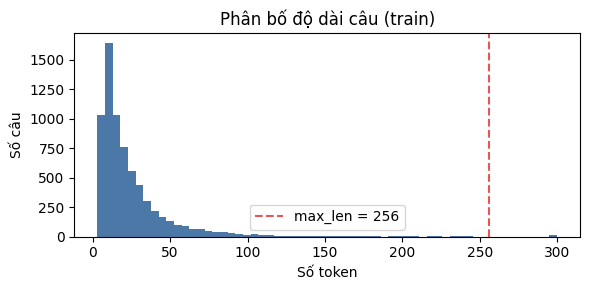

In [7]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

def load_with_fallback(fn, name, **kw):
    # Phòng trường hợp phiên bản transformers cần trust_remote_code
    try:
        return fn(name, **kw)
    except Exception as e:
        print(f'(thử lại với trust_remote_code=True do lỗi {type(e).__name__})')
        return fn(name, trust_remote_code=True, **kw)

tokenizer = load_with_fallback(AutoTokenizer.from_pretrained, MODEL_NAME)
lens = np.array([len(x) for x in tokenizer(list(train_df[TEXT_COL]))['input_ids']])
print(f'Số token mỗi câu: trung vị {int(np.median(lens))}, 95% câu ≤ {int(np.percentile(lens, 95))}, '
      f'dài nhất {lens.max()}')
print(f'Tỉ lệ câu bị cắt bớt ở max_len = {MAX_LEN}: {(lens > MAX_LEN).mean() * 100:.1f}%')
print('Ví dụ tách token:', tokenizer.tokenize(train_df[TEXT_COL].iloc[0])[:20])

plt.figure(figsize=(6, 3))
plt.hist(np.clip(lens, 0, 300), bins=60, color='#4C78A8')
plt.axvline(MAX_LEN, color='#E45756', ls='--', label=f'max_len = {MAX_LEN}')
plt.xlabel('Số token'); plt.ylabel('Số câu'); plt.title('Phân bố độ dài câu (train)'); plt.legend()
plt.tight_layout(); plt.show()

## 6. Dataset và DataLoader
Dùng *padding động*: mỗi batch chỉ được pad tới độ dài câu dài nhất trong batch đó. Vì đa số câu ngắn, cách này giúp train nhanh hơn nhiều so với pad mọi câu về `max_len`, nhất là khi chạy trên CPU.

In [8]:
from torch.utils.data import Dataset, DataLoader

class TextDataset(Dataset):
    def __init__(self, df):
        self.ids = tokenizer(list(df[TEXT_COL]), truncation=True, max_length=MAX_LEN)['input_ids']
        self.labels = df['label'].tolist()
    def __len__(self): return len(self.labels)
    def __getitem__(self, i): return self.ids[i], self.labels[i]

def collate(batch):
    L = max(len(x) for x, _ in batch)
    ids = torch.full((len(batch), L), tokenizer.pad_token_id, dtype=torch.long)
    att = torch.zeros((len(batch), L), dtype=torch.long)
    for i, (x, _) in enumerate(batch):
        ids[i, :len(x)] = torch.tensor(x); att[i, :len(x)] = 1
    return ids, att, torch.tensor([y for _, y in batch])

ds_train, ds_val, ds_test = TextDataset(train_df), TextDataset(val_df), TextDataset(test_df)
dl_val  = DataLoader(ds_val,  batch_size=BATCH_SIZE * 2, collate_fn=collate)
dl_test = DataLoader(ds_test, batch_size=BATCH_SIZE * 2, collate_fn=collate)
print(len(ds_train), len(ds_val), len(ds_test))

7000 1000 2000


## 7. Các hàm huấn luyện và đánh giá

- **Mất cân bằng lớp:** lớp toxic chỉ chiếm khoảng 3,4% tập train (240/7.000), nên dùng *weighted cross-entropy*. Trọng số lớp toxic bằng tỉ lệ số câu không toxic trên số câu toxic (khoảng 28), giới hạn tối đa 10.
- **Chọn epoch tốt nhất:** theo **PR-AUC trên val**. Không chọn theo F1, vì val chỉ có 45 câu toxic nên F1 dao động mạnh giữa các epoch.
- **Ngưỡng phân loại:** chọn trên **val** sao cho F1 lớp toxic cao nhất, sau đó giữ nguyên ngưỡng này khi đánh giá trên test.

In [9]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, average_precision_score,
                             roc_auc_score, confusion_matrix, precision_recall_curve)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

@torch.no_grad()
def predict_proba(model, loader):
    model.eval(); out = []
    for ids, att, _ in loader:
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
            logits = model(input_ids=ids.to(DEVICE), attention_mask=att.to(DEVICE)).logits
        out.append(torch.softmax(logits.float(), -1)[:, 1].cpu().numpy())
    return np.concatenate(out)

def best_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-9)
    i = int(np.nanargmax(f1[:-1]))
    return float(thr[i]), float(f1[i])

def evaluate(y, p, th):
    yhat = (p >= th).astype(int)
    return {'threshold': th,
            'accuracy': accuracy_score(y, yhat),
            'precision_toxic': precision_score(y, yhat, zero_division=0),
            'recall_toxic': recall_score(y, yhat, zero_division=0),
            'f1_toxic': f1_score(y, yhat, zero_division=0),
            'f1_macro': f1_score(y, yhat, average='macro', zero_division=0),
            'pr_auc': average_precision_score(y, p),
            'roc_auc': roc_auc_score(y, p),
            'confusion_matrix': confusion_matrix(y, yhat, labels=[0, 1]).tolist()}

def train_one_seed(seed):
    set_seed(seed)
    g = torch.Generator().manual_seed(seed)
    dl_train = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate, generator=g)
    model = load_with_fallback(AutoModelForSequenceClassification.from_pretrained, MODEL_NAME, num_labels=2).to(DEVICE)

    n0, n1 = int((train_df.label == 0).sum()), int((train_df.label == 1).sum())
    pos_w = min(n0 / n1, MAX_POS_WEIGHT)
    loss_fn = torch.nn.CrossEntropyLoss(weight=torch.tensor([1.0, pos_w], device=DEVICE))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    total = len(dl_train) * EPOCHS
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP * total), total)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    print(f'Trọng số lớp toxic = {pos_w:.1f} | {len(dl_train)} batch/epoch')

    best_ap, best_state, history, bad, t0 = -1, None, [], 0, time.time()
    for ep in range(1, EPOCHS + 1):
        model.train(); tot, n = 0.0, 0
        for step, (ids, att, y) in enumerate(dl_train, 1):
            ids, att, y = ids.to(DEVICE), att.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                logits = model(input_ids=ids, attention_mask=att).logits
            loss = loss_fn(logits.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(y); n += len(y)
            if ep == 1 and step == 20:
                per = (time.time() - t0) / 20
                print(f'  ~{per:.2f} giây/batch → ước tính {per * len(dl_train) / 60:.1f} phút/epoch, '
                      f'{per * total / 60:.1f} phút cho {EPOCHS} epoch')
        pv = predict_proba(model, dl_val)
        ap = average_precision_score(val_df.label, pv)
        th, f1 = best_threshold(val_df.label.values, pv)
        history.append({'epoch': ep, 'train_loss': tot / n, 'val_pr_auc': ap, 'val_best_f1': f1})
        print(f'  epoch {ep}: loss {tot / n:.4f} | val PR-AUC {ap:.3f} | val F1 tốt nhất {f1:.3f} '
              f'| {(time.time() - t0) / 60:.1f} phút')
        if ap > best_ap:
            best_ap, bad = ap, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                print('  dừng sớm (early stopping)'); break

    model.load_state_dict(best_state)
    pv = predict_proba(model, dl_val)
    th, _ = best_threshold(val_df.label.values, pv)
    pt = predict_proba(model, dl_test)
    return model, pd.DataFrame(history), evaluate(val_df.label.values, pv, th), evaluate(test_df.label.values, pt, th), \
           evaluate(test_df.label.values, pt, 0.5), pt, th

## 8. Huấn luyện
Trên GPU mất vài phút cho mỗi seed. Trên CPU có thể mất 1–3 giờ; sau 20 batch đầu notebook sẽ in thời gian ước tính.

In [10]:
results, histories, probs, thresholds = [], {}, {}, {}
best_model, best_val_ap = None, -1
for seed in SEEDS:
    print(f'\n===== seed {seed} =====')
    model, hist, rv, rt, rt05, pt, th = train_one_seed(seed)
    histories[seed], probs[seed], thresholds[seed] = hist, pt, th
    results.append({'seed': seed, 'val': rv, 'test': rt, 'test_threshold_0.5': rt05})
    print(f"  TEST (ngưỡng {th:.3f}): P {rt['precision_toxic']:.3f} | R {rt['recall_toxic']:.3f} | "
          f"F1 {rt['f1_toxic']:.3f} | PR-AUC {rt['pr_auc']:.3f}")
    if rv['pr_auc'] > best_val_ap:
        if best_model is not None: del best_model
        best_model, best_val_ap, best_seed = model, rv['pr_auc'], seed
    else:
        del model
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()


===== seed 42 =====


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  540MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  540MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

... (4 outputs left out)

Trọng số lớp toxic = 10.0 | 438 batch/epoch
  ~0.14 giây/batch → ước tính 1.0 phút/epoch, 5.2 phút cho 5 epoch
  epoch 1: loss 0.4344 | val PR-AUC 0.806 | val F1 tốt nhất 0.703 | 1.0 phút
  epoch 2: loss 0.2653 | val PR-AUC 0.839 | val F1 tốt nhất 0.745 | 1.9 phút
  epoch 3: loss 0.1424 | val PR-AUC 0.745 | val F1 tốt nhất 0.718 | 2.9 phút
  epoch 4: loss 0.0633 | val PR-AUC 0.769 | val F1 tốt nhất 0.727 | 3.8 phút
  dừng sớm (early stopping)
  TEST (ngưỡng 0.981): P 0.740 | R 0.720 | F1 0.730 | PR-AUC 0.804

===== seed 7 =====


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base-v2
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trọng số lớp toxic = 10.0 | 438 batch/epoch
  ~0.11 giây/batch → ước tính 0.8 phút/epoch, 4.1 phút cho 5 epoch
  epoch 1: loss 0.5171 | val PR-AUC 0.384 | val F1 tốt nhất 0.496 | 1.0 phút
  epoch 2: loss 0.4102 | val PR-AUC 0.600 | val F1 tốt nhất 0.642 | 1.9 phút
  epoch 3: loss 0.2772 | val PR-AUC 0.722 | val F1 tốt nhất 0.687 | 2.9 phút
  epoch 4: loss 0.1875 | val PR-AUC 0.751 | val F1 tốt nhất 0.710 | 3.8 phút
  epoch 5: loss 0.1252 | val PR-AUC 0.761 | val F1 tốt nhất 0.710 | 4.8 phút
  TEST (ngưỡng 0.018): P 0.636 | R 0.653 | F1 0.645 | PR-AUC 0.747


## 9. Kết quả trên tập test

In [11]:
keys = ['accuracy', 'precision_toxic', 'recall_toxic', 'f1_toxic', 'f1_macro', 'pr_auc', 'roc_auc']
names = ['Accuracy', 'Precision (toxic)', 'Recall (toxic)', 'F1 (toxic)', 'Macro-F1', 'PR-AUC', 'ROC-AUC']
per_seed = pd.DataFrame([{n: r['test'][k] for k, n in zip(keys, names)} for r in results],
                        index=[f'seed {r["seed"]}' for r in results])
table = per_seed.copy()
if len(results) > 1:
    table.loc['Trung bình'] = per_seed.mean()
    table.loc['Độ lệch chuẩn'] = per_seed.std(ddof=0)
display(table.round(3)) if 'display' in globals() else print(table.round(3))

json.dump({'config': {k: globals()[k] for k in ['MODEL_NAME', 'INPUT_MODE', 'NORMALIZE_TEENCODE', 'SEEDS', 'EPOCHS', 'BATCH_SIZE', 'LR',
                                                'MAX_LEN', 'MAX_POS_WEIGHT', 'PATIENCE']},
           'device': str(DEVICE), 'per_seed': results,
           'test_summary': {k: {'mean': float(per_seed[n].mean()), 'std': float(per_seed[n].std(ddof=0))}
                            for k, n in zip(keys, names)}},
          open(os.path.join(OUT_DIR, 'metrics.json'), 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
table.round(4).to_csv(os.path.join(OUT_DIR, 'ket_qua_test.csv'), encoding='utf-8-sig')
print('Đã lưu metrics.json và ket_qua_test.csv vào', OUT_DIR)

               Accuracy  Precision (toxic)  Recall (toxic)  F1 (toxic)  \
seed 42           0.979              0.770           0.627       0.691   
seed 13           0.980              0.740           0.720       0.730   
seed 7            0.973              0.636           0.653       0.645   
Trung bình        0.977              0.716           0.667       0.689   
Độ lệch chuẩn     0.003              0.057           0.039       0.035   

               Macro-F1  PR-AUC  ROC-AUC  
seed 42           0.840   0.691    0.941  
seed 13           0.860   0.804    0.979  
seed 7            0.815   0.747    0.977  
Trung bình        0.838   0.747    0.966  
Độ lệch chuẩn     0.018   0.046    0.018  
Đã lưu metrics.json và ket_qua_test.csv vào ./results/phobert_v2


### Confusion matrix và đường Precision-Recall (seed tốt nhất)

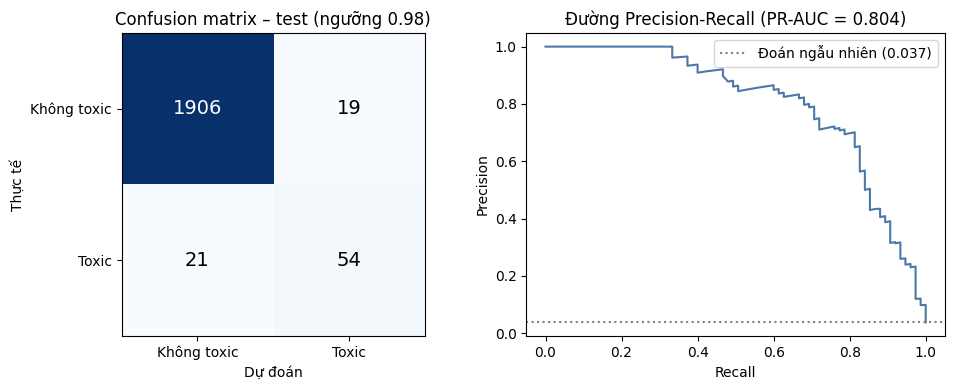

In [12]:
s = best_seed
pt, th = probs[s], thresholds[s]
cm = confusion_matrix(test_df.label, (pt >= th).astype(int), labels=[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=14,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xticks([0, 1], ['Không toxic', 'Toxic']); ax.set_yticks([0, 1], ['Không toxic', 'Toxic'])
ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thực tế'); ax.set_title(f'Confusion matrix – test (ngưỡng {th:.2f})')

prec, rec, _ = precision_recall_curve(test_df.label, pt)
axes[1].plot(rec, prec, color='#4C78A8')
axes[1].axhline(test_df.label.mean(), color='gray', ls=':', label=f'Đoán ngẫu nhiên ({test_df.label.mean():.3f})')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title(f'Đường Precision-Recall (PR-AUC = {average_precision_score(test_df.label, pt):.3f})')
axes[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'confusion_matrix_pr_curve.png'), dpi=150); plt.show()

### Đường học (learning curve)

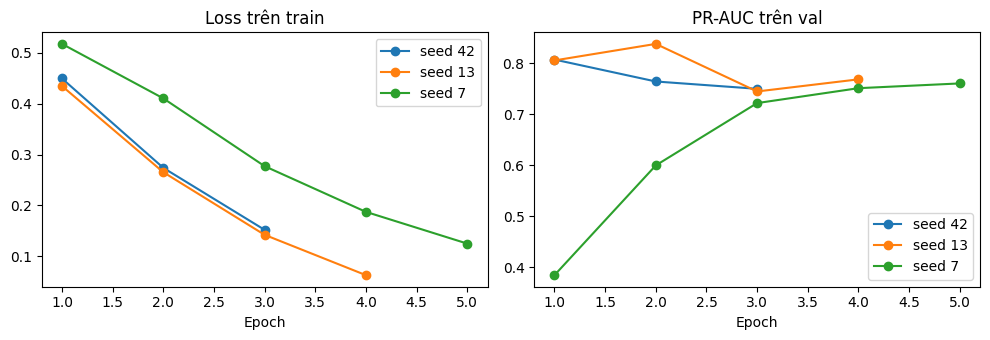

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for s, h in histories.items():
    axes[0].plot(h.epoch, h.train_loss, marker='o', label=f'seed {s}')
    axes[1].plot(h.epoch, h.val_pr_auc, marker='o', label=f'seed {s}')
axes[0].set_title('Loss trên train'); axes[1].set_title('PR-AUC trên val')
for a in axes: a.set_xlabel('Epoch'); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'learning_curve.png'), dpi=150); plt.show()

## 10. Phân tích lỗi
- **Bỏ sót (FN):** câu toxic nhưng mô hình đoán không toxic.
- **Báo nhầm (FP):** câu không toxic nhưng mô hình đoán toxic.

In [14]:
pred = test_df.copy()
pred['prob_toxic'] = probs[best_seed]
pred['pred'] = (pred.prob_toxic >= thresholds[best_seed]).astype(int)
pred.to_csv(os.path.join(OUT_DIR, 'predictions_test.csv'), index=False, encoding='utf-8-sig')
err = pred[pred.pred != pred.label].copy()
err['loai_loi'] = np.where(err.label == 1, 'Bỏ sót (FN)', 'Báo nhầm (FP)')
err.sort_values('prob_toxic', ascending=False).to_csv(os.path.join(OUT_DIR, 'errors_test.csv'), index=False, encoding='utf-8-sig')
print(err.loai_loi.value_counts().to_string(), '\n')
pd.set_option('display.max_colwidth', 160)
show = err[['loai_loi', 'prob_toxic', 'noi_dung_goc']].sort_values(['loai_loi', 'prob_toxic'], ascending=[True, False]).head(20)
display(show) if 'display' in globals() else print(show)

loai_loi
Bỏ sót (FN)      21
Báo nhầm (FP)    19 

           loai_loi  prob_toxic  \
202   Báo nhầm (FP)    0.990821   
1800  Báo nhầm (FP)    0.990587   
155   Báo nhầm (FP)    0.990514   
169   Báo nhầm (FP)    0.990178   
545   Báo nhầm (FP)    0.990121   
197   Báo nhầm (FP)    0.989986   
1624  Báo nhầm (FP)    0.989889   
1382  Báo nhầm (FP)    0.988536   
395   Báo nhầm (FP)    0.988039   
725   Báo nhầm (FP)    0.987923   
1589  Báo nhầm (FP)    0.987080   
276   Báo nhầm (FP)    0.986700   
718   Báo nhầm (FP)    0.986310   
362   Báo nhầm (FP)    0.985718   
538   Báo nhầm (FP)    0.984782   
185   Báo nhầm (FP)    0.984276   
631   Báo nhầm (FP)    0.984155   
1481  Báo nhầm (FP)    0.983182   
1190  Báo nhầm (FP)    0.982065   
1123    Bỏ sót (FN)    0.971966   

                                                                                                                                                         noi_dung_goc  
202   Không nên mua máy của 1 nhãn hàng lớn m

## 11. Xuất file nộp TV4
Theo `QUY_UOC_FILE_DU_DOAN.md`:
- `results/predictions/phobert.csv`: đúng 4 cột `review_id, label, score, pred`, đủ 2.000 dòng của `data/test.csv`. `score` là xác suất lớp toxic (`softmax(logits)[:, 1]`), `pred = score >= threshold`.
- `results/predictions/phobert_info.json`: ngưỡng, nơi chọn ngưỡng (`val`), siêu tham số, seed.

Khi chạy nhiều seed, file nộp lấy **seed có PR-AUC trên val cao nhất** (không chọn theo test). Trung bình ± độ lệch chuẩn qua các seed được ghi vào `ghi_chu` và `metrics.json` để đưa vào báo cáo.

In [15]:
score = probs[best_seed].astype(np.float64)   # float64: `score >= threshold` không đổi sau khi ghi/đọc lại CSV
th = float(thresholds[best_seed])
sub = pd.DataFrame({'review_id': test_df['review_id'], 'label': test_df['label'],
                    'score': score, 'pred': (score >= th).astype(int)})
sub.to_csv(os.path.join(PRED_DIR, 'phobert.csv'), index=False, encoding='utf-8')

rt = next(r['test'] for r in results if r['seed'] == best_seed)
h = histories[best_seed]
pos_w = min((train_df.label == 0).sum() / (train_df.label == 1).sum(), MAX_POS_WEIGHT)
summ = {k: (per_seed[n].mean(), per_seed[n].std(ddof=0)) for k, n in zip(keys, names)}
info = {
    'nguoi_phu_trach': 'TV3',
    'threshold': th,
    'chon_nguong_tren': 'val',
    'sieu_tham_so': {
        'backbone': 'vinai/phobert-base-v2',
        'training_mode': f'End-to-End Fine-Tuning (AdamW, {DEVICE.type.upper()})',
        'epochs_toi_da': EPOCHS, 'epoch_tot_nhat': int(h.loc[h.val_pr_auc.idxmax(), 'epoch']),
        'early_stopping_patience': PATIENCE,
        'lr': LR, 'warmup': WARMUP, 'batch_size': BATCH_SIZE, 'max_len': MAX_LEN,
        'loss': f'CrossEntropyLoss(weights=[1.0, {pos_w:.1f}])',
        'input_mode': INPUT_MODE, 'normalize_teencode': NORMALIZE_TEENCODE,
    },
    'random_seed': int(best_seed),
    'ghi_chu': (f'Fine-tune PhoBERT với các seed {SEEDS}; nộp seed {best_seed} (PR-AUC val cao nhất). '
                f"Test trung bình qua các seed: F1 toxic {summ['f1_toxic'][0]:.4f} ± {summ['f1_toxic'][1]:.4f}, "
                f"PR-AUC {summ['pr_auc'][0]:.4f} ± {summ['pr_auc'][1]:.4f}."),
    'metrics_test': {k: float(rt[k]) for k in keys},
}
json.dump(info, open(os.path.join(PRED_DIR, 'phobert_info.json'), 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
print(json.dumps(info, ensure_ascii=False, indent=2))

{
  "nguoi_phu_trach": "TV3",
  "threshold": 0.9811307191848755,
  "chon_nguong_tren": "val",
  "sieu_tham_so": {
    "backbone": "vinai/phobert-base-v2",
    "training_mode": "End-to-End Fine-Tuning (AdamW, CUDA)",
    "epochs_toi_da": 5,
    "epoch_tot_nhat": 2,
    "early_stopping_patience": 2,
    "lr": 2e-05,
    "warmup": 0.1,
    "batch_size": 16,
    "max_len": 256,
    "loss": "CrossEntropyLoss(weights=[1.0, 10.0])",
    "input_mode": "pyvi",
    "normalize_teencode": true
  },
  "random_seed": 13,
  "ghi_chu": "Fine-tune PhoBERT với các seed [42, 13, 7]; nộp seed 13 (PR-AUC val cao nhất). Test trung bình qua các seed: F1 toxic 0.6885 ± 0.0347, PR-AUC 0.7472 ± 0.0460.",
  "metrics_test": {
    "accuracy": 0.98,
    "precision_toxic": 0.7397260273972602,
    "recall_toxic": 0.72,
    "f1_toxic": 0.7297297297297297,
    "f1_macro": 0.8596727568690186,
    "pr_auc": 0.8037028032803354,
    "roc_auc": 0.9788051948051949
  }
}


In [16]:
# Tự kiểm tra theo mục 3 của quy ước (giống `python 4_model_evaluation.py --check results/predictions/phobert.csv`)
chk = pd.read_csv(os.path.join(PRED_DIR, 'phobert.csv'))
inf = json.load(open(os.path.join(PRED_DIR, 'phobert_info.json'), encoding='utf-8'))
errs = []
if list(chk.columns) != ['review_id', 'label', 'score', 'pred']: errs.append(f'Sai cột: {list(chk.columns)}')
if len(chk) != len(test_df) or chk.review_id.duplicated().any(): errs.append('Số dòng sai hoặc review_id bị lặp')
if set(chk.review_id) != set(test_df.review_id): errs.append('review_id không khớp với test.csv')
if chk.isnull().any().any() or not np.isfinite(chk.score).all(): errs.append('Có ô trống hoặc score không hữu hạn')
m = chk.set_index('review_id').loc[test_df.review_id]
if (m.label.values != test_df.label.values).any(): errs.append('label không khớp với test.csv')
n_bad = ((chk.score >= inf['threshold']).astype(int) != chk.pred).sum()
if n_bad: errs.append(f'{n_bad} dòng pred không khớp score >= threshold')
print('HỢP LỆ' if not errs else 'LỖI:\n- ' + '\n- '.join(errs))

HỢP LỆ


## 12. Thử mô hình với câu tự nhập

In [17]:
def predict_text(texts, model=best_model, th=thresholds[best_seed]):
    seg = [ViTokenizer.tokenize(normalize(t).lower()) if INPUT_MODE == 'tien_xu_ly' else segment(t) for t in texts]
    enc = tokenizer(seg, truncation=True, max_length=MAX_LEN, padding=True, return_tensors='pt')
    model.eval()
    with torch.no_grad():
        p = torch.softmax(model(**{k: v.to(DEVICE) for k, v in enc.items() if k in ('input_ids', 'attention_mask')}).logits.float(), -1)[:, 1].cpu().numpy()
    for t, pi in zip(texts, p):
        print(f"{'TOXIC     ' if pi >= th else 'không toxic'} ({pi:.3f})  {t}")

predict_text([
    'Máy chạy êm, giao hàng nhanh, rất hài lòng',
    'Sản phẩm quá tệ, bảo hành chậm, không nên mua',
    'Bọn bán hàng lừa đảo, hàng đểu mà giá cắt cổ',
    'Gọi tổng đài cả ngày đéo ai nghe máy',
])

không toxic (0.002)  Máy chạy êm, giao hàng nhanh, rất hài lòng
không toxic (0.003)  Sản phẩm quá tệ, bảo hành chậm, không nên mua
TOXIC      (0.992)  Bọn bán hàng lừa đảo, hàng đểu mà giá cắt cổ
TOXIC      (0.985)  Gọi tổng đài cả ngày đéo ai nghe máy


## 13. Lưu mô hình
Mô hình được lưu vào `results/phobert_v2/best_model`. Có thể nạp lại bằng `AutoModelForSequenceClassification.from_pretrained('results/phobert_v2/best_model')`. Khi dùng lại, nhớ tách từ câu mới bằng hàm `segment()` ở mục 4.

In [18]:
if SAVE_MODEL:
    path = os.path.join(OUT_DIR, 'best_model')
    best_model.save_pretrained(path); tokenizer.save_pretrained(path)
    json.dump({'threshold': thresholds[best_seed], 'max_len': MAX_LEN, 'seed': best_seed,
               'input_mode': INPUT_MODE, 'normalize_teencode': NORMALIZE_TEENCODE},
              open(os.path.join(path, 'threshold.json'), 'w'))
    print('Đã lưu mô hình vào', os.path.abspath(path))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Đã lưu mô hình vào /kaggle/working/results/phobert_v2/best_model


## 14. Nén kết quả để tải về
Tạo `results_phobert_v2.zip` chứa thư mục `results/` (file nộp TV4 và kết quả chi tiết), **trừ** `best_model/` (khoảng 540 MB, không nên đưa vào git). Tải file zip ở tab Output rồi **giải nén vào thư mục gốc repo**: file sẽ nằm đúng ở `results/predictions/phobert.csv` và `results/phobert_v2/`.

In [19]:
import zipfile

with zipfile.ZipFile('results_phobert_v2.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for d in (OUT_DIR, PRED_DIR):
        for root, dirs, files in os.walk(d):
            dirs[:] = [x for x in dirs if x != 'best_model']
            for f in files:
                p = os.path.join(root, f)
                z.write(p, os.path.relpath(p, ROOT))
    print('\n'.join(z.namelist()))
print('Đã tạo', os.path.abspath('results_phobert_v2.zip'))

results/phobert_v2/learning_curve.png
results/phobert_v2/metrics.json
results/phobert_v2/predictions_test.csv
results/phobert_v2/confusion_matrix_pr_curve.png
results/phobert_v2/ket_qua_test.csv
results/phobert_v2/errors_test.csv
results/predictions/phobert_info.json
results/predictions/phobert.csv
Đã tạo /kaggle/working/results_phobert_v2.zip
